<h1><center>Сеть YOLO

Сеть хранит сами изображения, окошки объектов.
Пытается предсказывать тип объекта и ограничивающую рамку.
Окошки содержат объект, если её уверенность выше, чем у соседей.
Естественно есть ещё множество штук.

<h2>Клонирование и компиляция Darknet

In [1]:
!git clone https://github.com/AlexeyAB/darknet

Cloning into 'darknet'...


In [ ]:
# %cd D:/MIREA/DPO/Learning/Practic2_9/darknet
# !sed -i 's/OPENCV=0/OPENCV=1/' Makefile
# !sed -i 's/GPU=0/GPU=1/' Makefile
# !sed -i 's/CUDNN=0/CUDNN=1/' Makefile
# !sed -i 's/CUDNN_HALF=0/CUDNN_HALF=1/' Makefile

# makefile_path = 'D:/MIREA/DPO/Learning/Practic2_9/darknet/Makefile'

# with open(makefile_path, 'r', encoding='utf-8') as file:
#     content = file.read()

# content = content.replace('OPENCV=0', 'OPENCV=1')
# content = content.replace('GPU=0', 'GPU=1')
# content = content.replace('CUDNN=0', 'CUDNN=1')
# content = content.replace('CUDNN_HALF=0', 'CUDNN_HALF=1')

# with open(makefile_path, 'w', encoding='utf-8') as file:
#     file.write(content)


In [2]:
!nvcc --version

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2022 NVIDIA Corporation
Built on Wed_Sep_21_10:41:10_Pacific_Daylight_Time_2022
Cuda compilation tools, release 11.8, V11.8.89
Build cuda_11.8.r11.8/compiler.31833905_0


In [3]:
!chcp 65001


Active code page: 65001


In [54]:
%cd D:/MIREA/DPO/Learning/Practic2_9/darknet

!rmdir /s /q build
!mkdir build
%cd build

!cmake -DENABLE_CUDA=ON -DENABLE_OPENCV=ON -DOpenCV_DIR="D:/ProgrammsForUniversity/OpenCV/opencv/build/x64/vc16/lib" -DCMAKE_CUDA_FLAGS="-allow-unsupported-compiler" -DCMAKE_CUDA_COMPILER="C:/Program Files/NVIDIA GPU Computing Toolkit/CUDA/v11.8/bin/nvcc.exe" ..
!cmake --build . --config Release

D:\MIREA\DPO\Learning\Practic2_9\darknet
D:\MIREA\DPO\Learning\Practic2_9\darknet\build
-- Building for: Visual Studio 17 2022
-- vcpkg not found, toolchain not defined, using integrated libs on win32
-- Selecting Windows SDK version 10.0.26100.0 to target Windows 10.0.26200.
-- The C compiler identification is MSVC 19.44.35214.0
-- The CXX compiler identification is MSVC 19.44.35214.0
-- Detecting C compiler ABI info
-- Detecting C compiler ABI info - done
-- Check for working C compiler: D:/Visual Studio Build Tools/VC/Tools/MSVC/14.44.35207/bin/Hostx64/x64/cl.exe - skipped
-- Detecting C compile features
-- Detecting C compile features - done
-- Detecting CXX compiler ABI info
-- Detecting CXX compiler ABI info - done
-- Check for working CXX compiler: D:/Visual Studio Build Tools/VC/Tools/MSVC/14.44.35207/bin/Hostx64/x64/cl.exe - skipped
-- Detecting CXX compile features
-- Detecting CXX compile features - done
-- The CUDA compiler identification is NVIDIA 11.8.89 with host compile

Darknet_VERSION: 0.2.5.7


Версия MSBuild 17.14.18+a338add32 для .NET Framework

  1>Checking Build System
  Building Custom Rule D:/MIREA/DPO/Learning/Practic2_9/darknet/CMakeLists.txt
  Compiling CUDA source file ..\src\activation_kernels.cu...
  
  (.venv3_11_8) D:\MIREA\DPO\Learning\Practic2_9\darknet\build>"C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v11.8\bin\nvcc.exe"  --use-local-env -ccbin "D:\Visual Studio Build Tools\VC\Tools\MSVC\14.44.35207\bin\HostX64\x64" -x cu -rdc=true  -ID:\MIREA\DPO\Learning\Practic2_9\darknet\include -ID:\MIREA\DPO\Learning\Practic2_9\darknet\src -ID:\MIREA\DPO\Learning\Practic2_9\darknet\3rdparty\stb\include -ID:\MIREA\DPO\Learning\Practic2_9\darknet\3rdparty\getopt -I"C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v11.8\include" -ID:\ProgrammsForUniversity\OpenCV\opencv\build\include -ID:\MIREA\DPO\Learning\Practic2_9\darknet\3rdparty\pthreads\include -I"C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v11.8\include"     --keep-dir dark\x64\Release  -maxrregcou

<h2>Загрузка преобученной сети

Ну там другое

<h2>Зададим вспомогательные функции

In [1]:
def imShow(path):
    import cv2
    import matplotlib.pyplot as plt
    %matplotlib inline

    image = cv2.imread(path)
    height, weight = image.shape[:2]
    resized_image = cv2.resize(image, (3 * weight, 3  * height), interpolation=cv2.INTER_CUBIC)

    fig = plt.gcf()
    fig.set_size_inches(18, 10)
    plt.axis('off')
    plt.imshow(cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB))
    plt.show()

# def upload():
#     from 

#     uploaded = 
#     for name, data in uploaded.items():
#         with open(name, 'wb') as f:
#             print('saved file', name)

# def download():
#     print('download')

In [40]:
%pwd

'D:\\MIREA\\DPO\\Learning\\Practic2_9\\darknet\\build'

<h2>Запускаем детектор Darknet

In [5]:
%cd D:/MIREA/DPO/Learning/Practic2_9/darknet
!darknet.exe detector test cfg/coco.data cfg/yolov4.cfg yolov4.weights data/person.jpg


D:\MIREA\DPO\Learning\Practic2_9\darknet
net.optimized_memory = 0 
mini_batch = 1, batch = 8, time_steps = 1, train = 0 
Create CUDA-stream - 0 
nms_kind: greedynms (1), beta = 0.600000 
nms_kind: greedynms (1), beta = 0.600000 
nms_kind: greedynms (1), beta = 0.600000 

 seen 64, trained: 32032 K-images (500 Kilo-batches_64) 
 Detection layer: 139 - type = 28 
 Detection layer: 150 - type = 28 
 Detection layer: 161 - type = 28 
data/person.jpg: Predicted in 100.995000 milli-seconds.
dog: 99%
person: 100%
horse: 98%


 CUDA-version: 11080 (13020), GPU count: 1  
 OpenCV version: 4.10.0
 0 : compute_capability = 860, cudnn_half = 0, GPU: NVIDIA GeForce RTX 3050 Laptop GPU 
   layer   filters  size/strd(dil)      input                output
   0 conv     32       3 x 3/ 1    608 x 608 x   3 ->  608 x 608 x  32 0.639 BF
   1 conv     64       3 x 3/ 2    608 x 608 x  32 ->  304 x 304 x  64 3.407 BF
   2 conv     64       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  64 0.757 BF
   3 route  1 		                           ->  304 x 304 x  64 
   4 conv     64       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  64 0.757 BF
   5 conv     32       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  32 0.379 BF
   6 conv     64       3 x 3/ 1    304 x 304 x  32 ->  304 x 304 x  64 3.407 BF
   7 Shortcut Layer: 4,  wt = 0, wn = 0, outputs: 304 x 304 x  64 0.006 BF
   8 conv     64       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  64 0.757 BF
   9 route  8 2 	                           ->  304 x 304 x 128 
  10 conv  

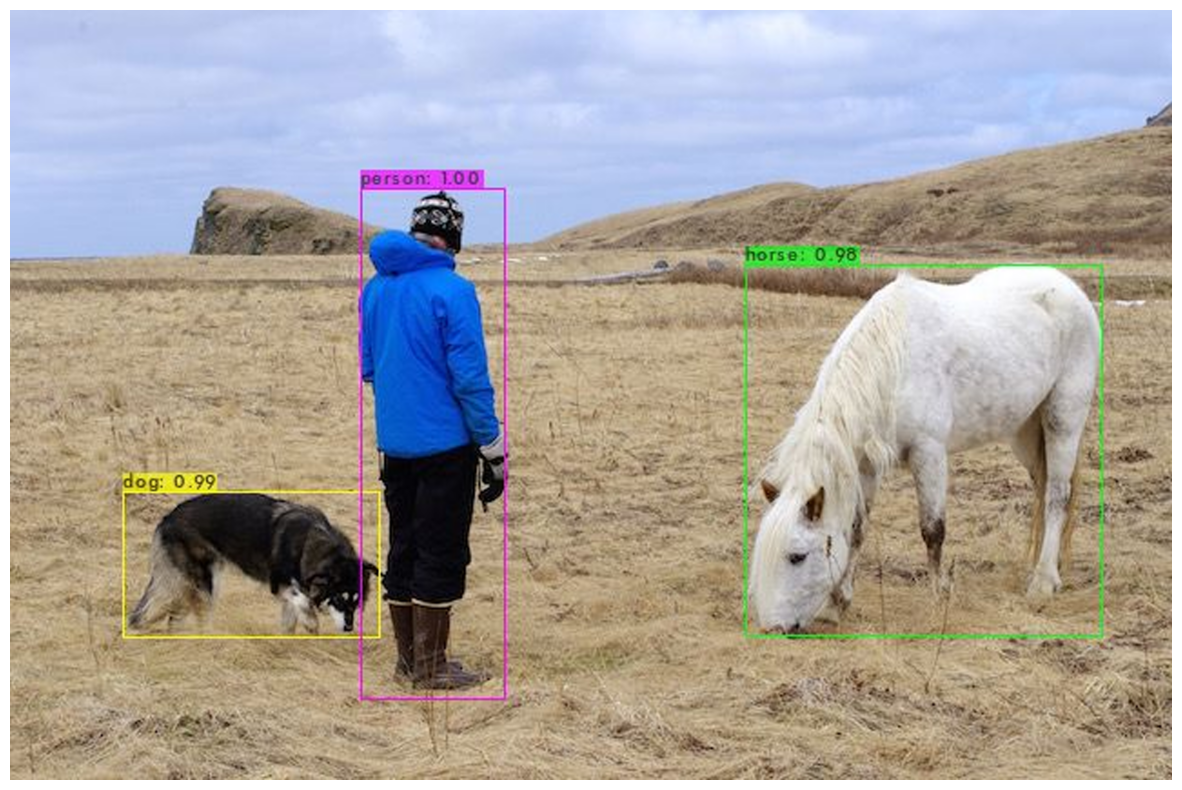

In [6]:
imShow('predictions.jpg')

<h2>Загрузка своего изображения и детекция

In [7]:
%cd D:/MIREA/DPO/Learning/Practic2_9/darknet
!darknet.exe detector test cfg/coco.data cfg/yolov4.cfg yolov4.weights data/dog_with_cat.jpg


D:\MIREA\DPO\Learning\Practic2_9\darknet
net.optimized_memory = 0 
mini_batch = 1, batch = 8, time_steps = 1, train = 0 
Create CUDA-stream - 0 
nms_kind: greedynms (1), beta = 0.600000 
nms_kind: greedynms (1), beta = 0.600000 
nms_kind: greedynms (1), beta = 0.600000 

 seen 64, trained: 32032 K-images (500 Kilo-batches_64) 
 Detection layer: 139 - type = 28 
 Detection layer: 150 - type = 28 
 Detection layer: 161 - type = 28 
data/dog_with_cat.jpg: Predicted in 101.817000 milli-seconds.
cat: 89%


 CUDA-version: 11080 (13020), GPU count: 1  
 OpenCV version: 4.10.0
 0 : compute_capability = 860, cudnn_half = 0, GPU: NVIDIA GeForce RTX 3050 Laptop GPU 
   layer   filters  size/strd(dil)      input                output
   0 conv     32       3 x 3/ 1    608 x 608 x   3 ->  608 x 608 x  32 0.639 BF
   1 conv     64       3 x 3/ 2    608 x 608 x  32 ->  304 x 304 x  64 3.407 BF
   2 conv     64       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  64 0.757 BF
   3 route  1 		                           ->  304 x 304 x  64 
   4 conv     64       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  64 0.757 BF
   5 conv     32       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  32 0.379 BF
   6 conv     64       3 x 3/ 1    304 x 304 x  32 ->  304 x 304 x  64 3.407 BF
   7 Shortcut Layer: 4,  wt = 0, wn = 0, outputs: 304 x 304 x  64 0.006 BF
   8 conv     64       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  64 0.757 BF
   9 route  8 2 	                           ->  304 x 304 x 128 
  10 conv  

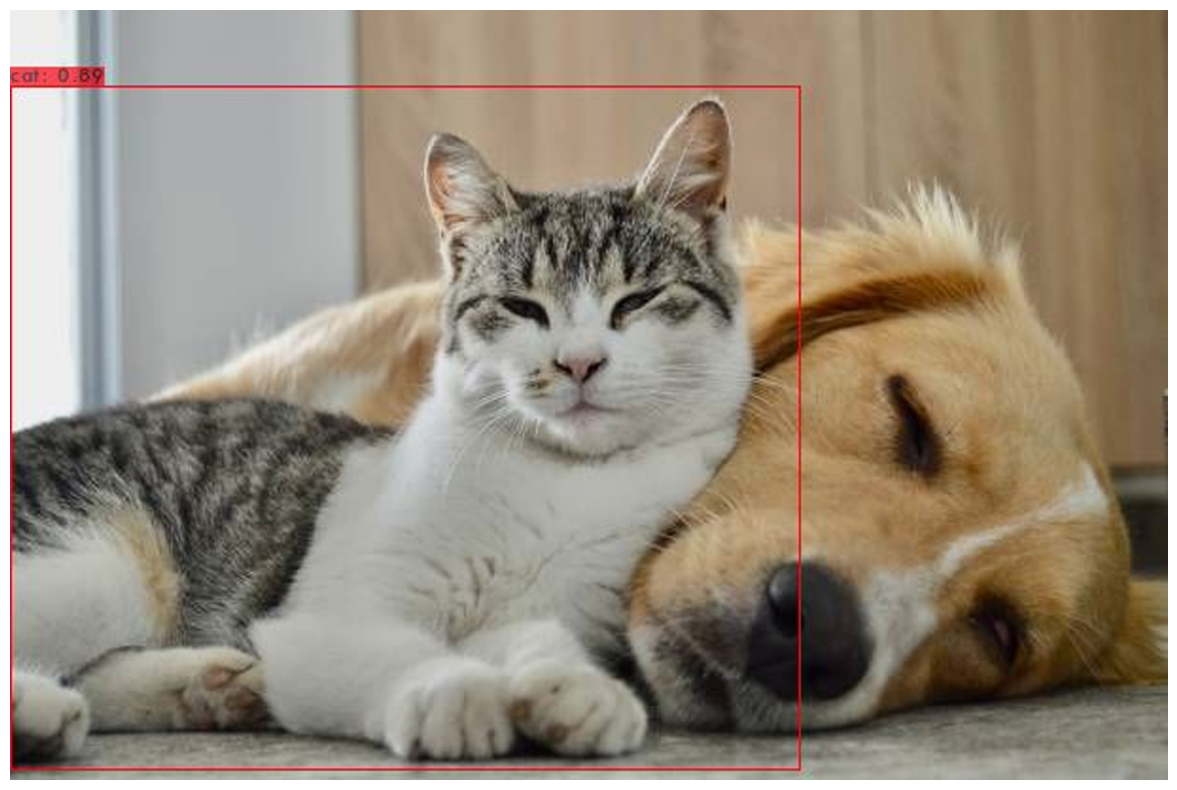

In [8]:
imShow('predictions.jpg')

In [9]:
%cd D:/MIREA/DPO/Learning/Practic2_9/darknet
!darknet.exe detector test cfg/coco.data cfg/yolov4.cfg yolov4.weights data/elephants.jpg


D:\MIREA\DPO\Learning\Practic2_9\darknet
net.optimized_memory = 0 
mini_batch = 1, batch = 8, time_steps = 1, train = 0 
Create CUDA-stream - 0 
nms_kind: greedynms (1), beta = 0.600000 
nms_kind: greedynms (1), beta = 0.600000 
nms_kind: greedynms (1), beta = 0.600000 

 seen 64, trained: 32032 K-images (500 Kilo-batches_64) 
 Detection layer: 139 - type = 28 
 Detection layer: 150 - type = 28 
 Detection layer: 161 - type = 28 
data/elephants.jpg: Predicted in 101.812000 milli-seconds.
elephant: 96%
elephant: 96%
elephant: 100%
elephant: 99%
elephant: 89%


 CUDA-version: 11080 (13020), GPU count: 1  
 OpenCV version: 4.10.0
 0 : compute_capability = 860, cudnn_half = 0, GPU: NVIDIA GeForce RTX 3050 Laptop GPU 
   layer   filters  size/strd(dil)      input                output
   0 conv     32       3 x 3/ 1    608 x 608 x   3 ->  608 x 608 x  32 0.639 BF
   1 conv     64       3 x 3/ 2    608 x 608 x  32 ->  304 x 304 x  64 3.407 BF
   2 conv     64       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  64 0.757 BF
   3 route  1 		                           ->  304 x 304 x  64 
   4 conv     64       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  64 0.757 BF
   5 conv     32       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  32 0.379 BF
   6 conv     64       3 x 3/ 1    304 x 304 x  32 ->  304 x 304 x  64 3.407 BF
   7 Shortcut Layer: 4,  wt = 0, wn = 0, outputs: 304 x 304 x  64 0.006 BF
   8 conv     64       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  64 0.757 BF
   9 route  8 2 	                           ->  304 x 304 x 128 
  10 conv  

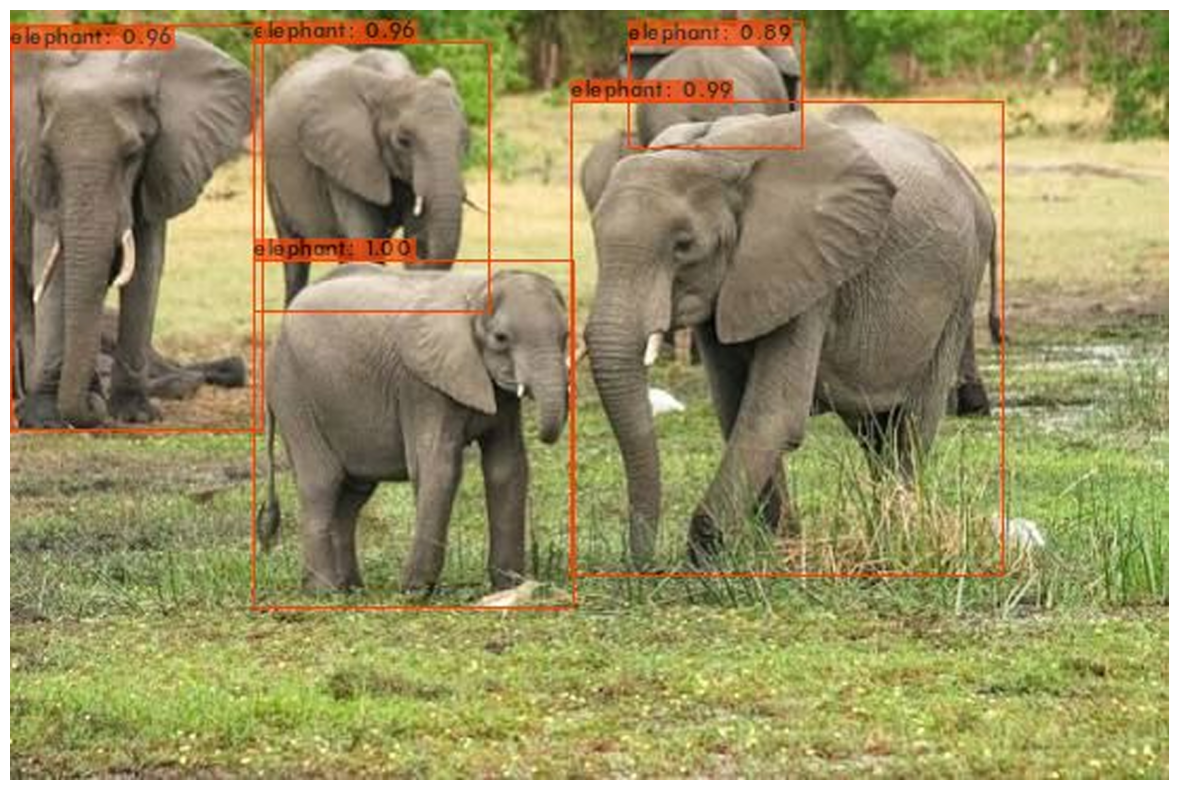

In [10]:
imShow('predictions.jpg')

<h2>Детектирование в видео в файле

In [48]:
import urllib.request

output_video_path = 'D:/MIREA/DPO/Learning/Practic2_9/cats.mp4'

video_url = 'https://drive.google.com/uc?id=1C9jGtApGQYElugUShLdXnIbPnvvHsqdW'

try:
    urllib.request.urlretrieve(video_url, output_video_path)
except Exception as e:
    print(f'Error: {e}')

In [3]:
%cd D:/MIREA/DPO/Learning/Practic2_9/darknet
!darknet.exe detector demo cfg/coco.data cfg/yolov4.cfg yolov4.weights data/cats.mp4 -i 0 -out_filename result.avi -thresh 0.5 -dont_show > log.txt

D:\MIREA\DPO\Learning\Practic2_9\darknet


 CUDA-version: 11080 (13020), GPU count: 1  
 OpenCV version: 4.10.0
 0 : compute_capability = 860, cudnn_half = 0, GPU: NVIDIA GeForce RTX 3050 Laptop GPU 
   layer   filters  size/strd(dil)      input                output
   0 conv     32       3 x 3/ 1    608 x 608 x   3 ->  608 x 608 x  32 0.639 BF
   1 conv     64       3 x 3/ 2    608 x 608 x  32 ->  304 x 304 x  64 3.407 BF
   2 conv     64       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  64 0.757 BF
   3 route  1 		                           ->  304 x 304 x  64 
   4 conv     64       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  64 0.757 BF
   5 conv     32       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  32 0.379 BF
   6 conv     64       3 x 3/ 1    304 x 304 x  32 ->  304 x 304 x  64 3.407 BF
   7 Shortcut Layer: 4,  wt = 0, wn = 0, outputs: 304 x 304 x  64 0.006 BF
   8 conv     64       1 x 1/ 1    304 x 304 x  64 ->  304 x 304 x  64 0.757 BF
   9 route  8 2 	                           ->  304 x 304 x 128 
  10 conv  

In [9]:
import cv2


video_path = 'D:/MIREA/DPO/Learning/Practic2_9/darknet/result.avi'

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Ошибка! Не удалось открыть видеофайл. Проверьте путь.")
else:
    print("Видео открыто. Нажмите клавишу 'Q' на клавиатуре, чтобы закрыть окно.")

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
        
    cv2.imshow('YOLOv4 Detection Result', frame)
    
    if cv2.waitKey(25) & 0xFF == ord('q'):
        break

cap.release()

Видео открыто. Нажмите клавишу 'Q' на клавиатуре, чтобы закрыть окно.


error: OpenCV(4.12.0) D:\a\opencv-python\opencv-python\opencv\modules\highgui\src\window.cpp:1301: error: (-2:Unspecified error) The function is not implemented. Rebuild the library with Windows, GTK+ 2.x or Cocoa support. If you are on Ubuntu or Debian, install libgtk2.0-dev and pkg-config, then re-run cmake or configure script in function 'cvShowImage'


<h1><center>Практическое задание</h1></center>

1. Возьмите любую Faster RCNN сеть и сравниет её с YOLO при детекции на ваших изображениях
2. Сделайте то же самое, но для видеоряда, оцените разности и точности